# Frozen ESC-50 Models on External FSD Recordings

## Summary

The frozen PANNs classifier achieved **45.17% accuracy** on 259 external recordings across six mapped categories, versus **20.08%** for the mean of three frozen noise-trained CNNs. The paired difference is **+25.10 pp [+19.82, +30.63]**, a conditional 95% recording-bootstrap interval. PANNs macro recall is **46.40%** and macro-F1 **58.07%**. All 50 model outputs remained active.

Five known ESC-50 recording IDs were excluded before inference. This result concerns a mapped external subset; it does not guarantee absence of perceptual duplicates or pretraining exposure. **No new training or added-noise evaluation** occurred.

## Context & Methods

This evaluation asks whether the existing PANNs classifier retains its comparative accuracy advantage on recordings from a different curated dataset. It uses the manually verified **FSDnoisy18k v1.0 test partition**, with six mapped categories and known ESC-50 recording IDs excluded. No model is fitted, selected or calibrated here.

The [fixed protocol](../reports/external_fsd_20261105/protocol.json) was written before external model predictions. [Previous complete study](ESC50_Results.ipynb) · [Earlier matched robustness experiment](ESC50_Transfer_Followup.ipynb).

### Key Assumptions

- The six mapping choices are semantic correspondences, not identical class definitions: clapping, engine, fireworks, rain, wind and footsteps. Broader or ambiguous classes such as Fire and Glass are excluded.
- “Clean” in FSDnoisy18k refers to verified labels, not absence of acoustic background noise. This experiment adds no noise and is not a realistic-noise stress panel.
- Known recording-ID exclusion covers all 2,000 ESC-50 metadata rows. It does not eliminate reuploads, shared uploaders, perceptual duplicates or possible AudioSet pretraining overlap.
- Each full recording is resampled to 16 kHz and divided into consecutive five-second windows, padding only the final fragment. The recording probability is the window-probability mean **weighted by unpadded duration**. The argmax always covers **all 50 ESC-50 classes**. A prediction outside the six target labels is an error.
- The primary contrast is PANNs accuracy minus the mean accuracy of three fixed noise-CNN fits. This mean is not a voting ensemble. Paired bootstrap intervals resample recording IDs (4,000 replicates); each ID occurs once, so this is recording-level resampling, not uploader-level uncertainty.

Official sources: [dataset and licenses](https://zenodo.org/records/2529934), [Fonseca et al., ICASSP 2019, Section 2](https://arxiv.org/html/1901.01189). This is a mapped six-class transfer check, not the original 20-class FSD benchmark or independent confirmation across all 50 ESC-50 classes.

In [1]:
from pathlib import Path
import sys,os,subprocess,json,zipfile
from datetime import datetime,timezone
RUN_EXTERNAL=True
candidates=[Path.cwd(),Path.cwd().parent,Path.cwd()/"research/esc50_improvements",Path("/content/esc50_external")]
ROOT=next((p for p in candidates if (p/"scripts/run_external_fsd.py").exists()),None)
if ROOT is None:
    ROOT=Path("/content/esc50_external")
    if Path("/content/external_project.zip").exists():
        with zipfile.ZipFile("/content/external_project.zip") as archive:archive.extractall(ROOT)
    else:subprocess.run(["git","clone","--depth","1","https://github.com/Richardafcs/esc-50-sound-classification.git",str(ROOT)],check=True,capture_output=True,timeout=180)
os.chdir(ROOT);sys.path[:0]=[str(ROOT),str(ROOT/"src")]
DATA=ROOT/"reports/external_fsd_20261105"
OUT=ROOT/"results/runs/external_fsd_20261105"
print("Execution started (UTC):",datetime.now(timezone.utc).isoformat())
print("Project:",ROOT.name)

Execution started (UTC): 2026-11-05T04:30:44.665509+00:00
Project: esc50_external


In [2]:
subprocess.run([sys.executable,"-m","pip","install","-q","torchlibrosa==0.1.0","librosa==0.11.0","scikit-learn==1.6.1","soundfile>=0.13","pandas>=2.2","matplotlib>=3.9"],check=True,capture_output=True,text=True,timeout=360)
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
plt.rcParams.update({"font.size":11,"figure.figsize":(10,5),"axes.spines.top":False,"axes.spines.right":False})
def table(frame,precision=2):
    display(frame.style.format(precision=precision,na_rep="—").hide(axis="index"))
print("Runtime:",torch.__version__,np.__version__,torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Runtime: 2.11.0+cu130 2.4.6 Tesla T4


## Data

The eligible metadata includes 264 recordings in the six categories. Five known ESC-50 recording IDs are excluded, leaving **259 unique recording IDs**. The excluded-ID table remains inspectable; no exclusions depend on model performance.

In [3]:
manifest=pd.read_csv(DATA/"manifest.csv",dtype={"src_file":str})
excluded=pd.read_csv(DATA/"excluded_recording_ids.csv",dtype={"src_file":str})
counts=manifest.groupby(["fsd_label","category","target"]).size().reset_index(name="Recordings")
table(counts)
table(excluded[["filename","fsd_label","category"]])
protocol=json.loads((DATA/"protocol.json").read_text())
print("Frozen models:",len(protocol["models"]),"New fits:",0,"Retained:",len(manifest),"Excluded:",len(excluded))

fsd_label,category,target,Recordings
Clapping,clapping,22,57
Engine,engine,44,48
Fireworks,fireworks,48,30
Rain,rain,10,32
Walk_or_footsteps,footsteps,25,52
Wind,wind,16,40


filename,fsd_label,category
12653.wav,Rain,rain
16746.wav,Rain,rain
73260.wav,Rain,rain
90797.wav,Rain,rain
235507.wav,Engine,engine


Frozen models: 4 New fits: 0 Retained: 259 Excluded: 5


### Acquire official inputs and run once

A fresh GPU run downloads the official PANNs source/checkpoint and the 304 MB FSD test archive, extracting only eligible recordings. The published original heads and CNN weights are reused. No ESC-50 WAV is needed. Completed outputs are reused, without repeating inference.

In [4]:
import urllib.request
ASSETS=Path("/content/esc50_external_assets") if Path("/content").exists() else ROOT/"results/external_assets"
if RUN_EXTERNAL and not (OUT/"summary.json").exists():
    if not torch.cuda.is_available():raise RuntimeError("Select a Colab GPU runtime or set RUN_EXTERNAL=False to read published results.")
    ASSETS.mkdir(parents=True,exist_ok=True)
    repository=ASSETS/"audioset_tagging_cnn"
    if not repository.exists():subprocess.run(["git","clone","--depth","1","https://github.com/qiuqiangkong/audioset_tagging_cnn.git",str(repository)],check=True,capture_output=True,timeout=180)
    def download(url,destination):
        if not destination.exists():subprocess.run(["curl","-fsSL","--retry","2","--max-time","600","-o",str(destination),url],check=True,capture_output=True,timeout=650)
    download("https://zenodo.org/records/3987831/files/Cnn14_16k_mAP%3D0.438.pth?download=1",ASSETS/"Cnn14_16k_mAP=0.438.pth")
    archive=ASSETS/"FSDnoisy18k.audio_test.zip"
    download("https://zenodo.org/records/2529934/files/FSDnoisy18k.audio_test.zip?download=1",archive)
    audio=ASSETS/"audio";audio.mkdir(exist_ok=True)
    wanted=set(manifest.filename)
    with zipfile.ZipFile(archive) as zipped:
        for member in zipped.infolist():
            filename=Path(member.filename).name
            if filename in wanted and not member.is_dir():(audio/filename).write_bytes(zipped.read(member))
    print("Official inputs ready:",len(list(audio.glob("*.wav"))),"eligible recordings.")
else:print("Using completed or published external results.")

Using completed or published external results.


In [5]:
if RUN_EXTERNAL:
    result=subprocess.run([sys.executable,"scripts/run_external_fsd.py","--assets",str(ASSETS),"--audio",str(ASSETS/"audio"),"--output",str(OUT),"--device","cuda"],capture_output=True,text=True,timeout=1900)
    if result.returncode:raise RuntimeError(result.stdout[-1500:]+result.stderr[-3000:])
    print(result.stdout[-700:])
    import shutil
    for filename in ["summary.json","metrics.csv","per_class.csv","predictions.csv","paired_effects.csv","recordings.csv"]:shutil.copy2(OUT/filename,DATA/filename)
summary=json.loads((DATA/"summary.json").read_text())
print("Completed:",summary["recordings"],"recordings;",summary["windows"],"windows;",summary["fits"],"fits;",round(summary["inference_seconds"],2),"inference seconds (setup/downloads excluded).")

Completed external evaluation exists; reusing its outputs.

Completed: 259 recordings; 534 windows; 0 fits; 28.98 inference seconds (setup/downloads excluded).


## Results

Accuracy is calculated once per recording over the full 50-class output space. Macro recall and macro-F1 average the six mapped target categories; predictions outside these categories remain errors. Three-fit means are averages of model metrics, not ensemble predictions.

In [6]:
metrics=pd.read_csv(DATA/"metrics.csv")
labels={"panns_lr":"PANNs + original LR","noise_cnn_s101":"Noise CNN · seed 101","noise_cnn_s202":"Noise CNN · seed 202","noise_cnn_s303":"Noise CNN · seed 303"}
columns=["accuracy","macro_recall","macro_f1","outside_target_rate"]
shown=metrics[["model","recordings","correct"]+columns].copy()
shown[columns]=100*shown[columns]
shown["model"]=shown.model.map(labels)
shown=shown.rename(columns={"model":"System","accuracy":"Accuracy (%)","macro_recall":"Macro recall (%)","macro_f1":"Macro-F1 (%)","outside_target_rate":"Outside six labels (%)"})
table(shown)
noise=metrics[metrics.model.str.startswith("noise_cnn")]
table(pd.DataFrame({"Metric":columns,"Noise-CNN mean (%)":[100*noise[c].mean() for c in columns],"Sample SD (pp)":[100*noise[c].std(ddof=1) for c in columns]}))

System,recordings,correct,Accuracy (%),Macro recall (%),Macro-F1 (%),Outside six labels (%)
PANNs + original LR,259,117,45.17,46.40,58.07,50.97
Noise CNN · seed 101,259,49,18.92,18.91,28.65,71.43
Noise CNN · seed 202,259,56,21.62,21.74,33.38,72.97
Noise CNN · seed 303,259,51,19.69,20.24,30.43,71.81


Metric,Noise-CNN mean (%),Sample SD (pp)
accuracy,20.08,1.39
macro_recall,20.30,1.42
macro_f1,30.82,2.39
outside_target_rate,72.07,0.80


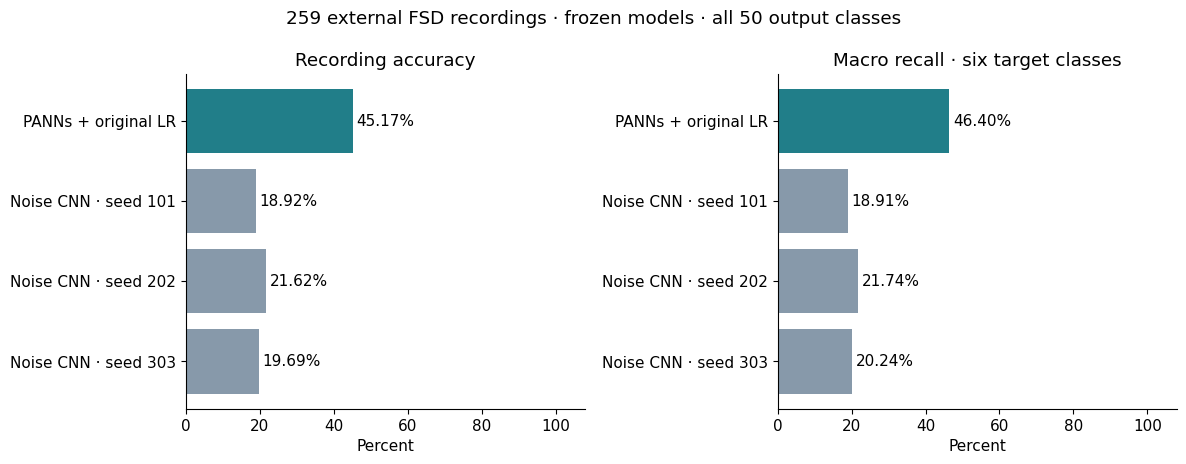

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4.7))
for ax,column,title in zip(axes,["accuracy","macro_recall"],["Recording accuracy","Macro recall · six target classes"]):
    values=100*metrics[column].to_numpy()
    ax.barh(range(4),values,color=["#217e89","#8799aa","#8799aa","#8799aa"])
    ax.set_yticks(range(4),[labels[m] for m in metrics.model]);ax.invert_yaxis();ax.set_xlim(0,108);ax.set_xlabel("Percent");ax.set_title(title)
    for i,value in enumerate(values):ax.text(value+1,i,f"{value:.2f}%",va="center")
fig.suptitle("259 external FSD recordings · frozen models · all 50 output classes")
fig.tight_layout();fig.savefig(DATA/"external_accuracy.png",dpi=180);plt.show()

Comparison,Difference (pp),95% lower,95% upper
panns_minus_mean_noise_cnn,25.10,19.82,30.63
panns_minus_noise_cnn_s101,26.25,20.46,32.05
panns_minus_noise_cnn_s202,23.55,18.15,28.96
panns_minus_noise_cnn_s303,25.48,20.08,31.27


PANNs minus the mean of three noise-CNN accuracies: **+25.10 pp [+19.82, +30.63]**. The interval is conditional on fixed systems and the mapped external recording population; it does not include uploader dependence, label-mapping or pretraining-exposure uncertainty.

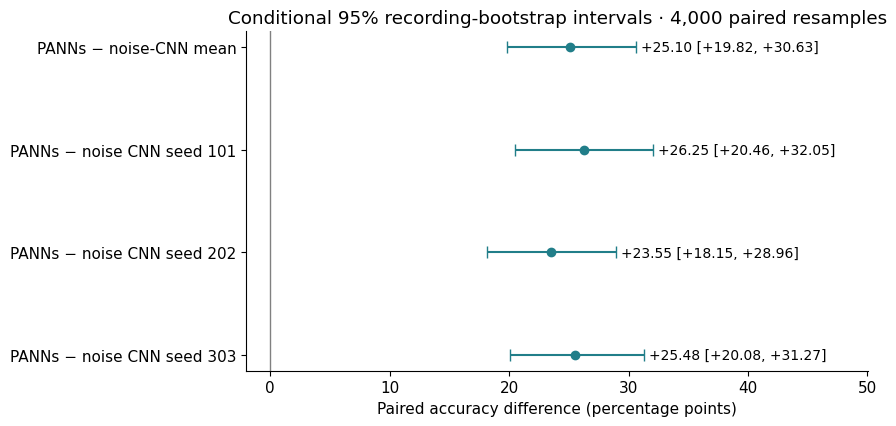

In [8]:
effects=pd.read_csv(DATA/"paired_effects.csv")
table(effects.rename(columns={"comparison":"Comparison","delta_pp":"Difference (pp)","low_pp":"95% lower","high_pp":"95% upper"}))
primary=effects.iloc[0]
display(Markdown(f"PANNs minus the mean of three noise-CNN accuracies: **{primary.delta_pp:+.2f} pp [{primary.low_pp:+.2f}, {primary.high_pp:+.2f}]**. The interval is conditional on fixed systems and the mapped external recording population; it does not include uploader dependence, label-mapping or pretraining-exposure uncertainty."))
fig,ax=plt.subplots(figsize=(9,4.4));names=["PANNs − noise-CNN mean","PANNs − noise CNN seed 101","PANNs − noise CNN seed 202","PANNs − noise CNN seed 303"]
for i,row in effects.iterrows():
    ax.errorbar(row.delta_pp,i,xerr=[[row.delta_pp-row.low_pp],[row.high_pp-row.delta_pp]],fmt="o",capsize=4,color="#217e89")
    ax.text(row.high_pp+.4,i,f"{row.delta_pp:+.2f} [{row.low_pp:+.2f}, {row.high_pp:+.2f}]",va="center",fontsize=10)
ax.axvline(0,color="gray",linewidth=1);ax.set_yticks(range(4),names);ax.invert_yaxis();ax.set_xlim(min(0,effects.low_pp.min())-2,effects.high_pp.max()+18);ax.set_xlabel("Paired accuracy difference (percentage points)");ax.set_title("Conditional 95% recording-bootstrap intervals · 4,000 paired resamples")
fig.tight_layout();fig.savefig(DATA/"external_paired_effects.png",dpi=180);plt.show()

### Class-specific performance

The categories and counts were fixed before predictions. Class differences are descriptive slices of a small external subset, not a basis for remapping labels after evaluation.

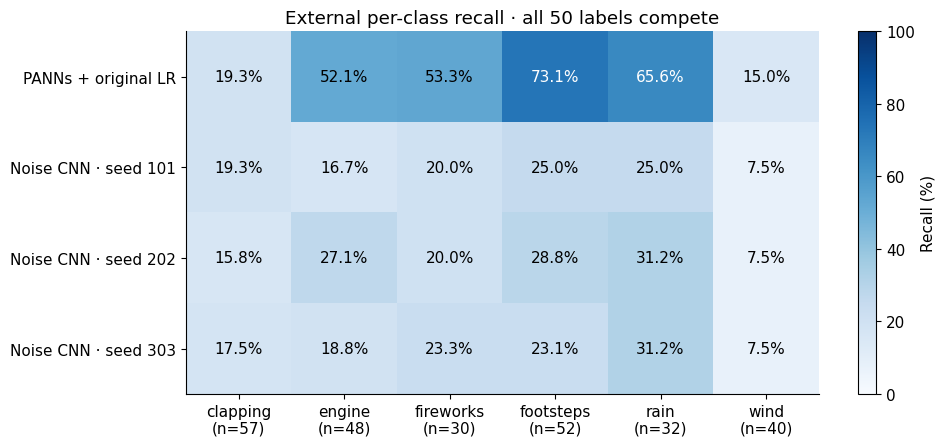

model,target,category,recordings,recall_percent
panns_lr,10,rain,32,65.62
panns_lr,16,wind,40,15.00
panns_lr,22,clapping,57,19.30
panns_lr,25,footsteps,52,73.08
panns_lr,44,engine,48,52.08
panns_lr,48,fireworks,30,53.33
noise_cnn_s101,10,rain,32,25.00
noise_cnn_s101,16,wind,40,7.50
noise_cnn_s101,22,clapping,57,19.30
noise_cnn_s101,25,footsteps,52,25.00


In [9]:
per_class=pd.read_csv(DATA/"per_class.csv")
recall=100*per_class.pivot(index="model",columns="category",values="recall").reindex(metrics.model)
count_lookup=manifest.groupby("category").size()
fig,ax=plt.subplots(figsize=(10,4.6));heat=ax.imshow(recall.to_numpy(),vmin=0,vmax=100,cmap="Blues",aspect="auto")
ax.set_xticks(range(len(recall.columns)),[f"{c.replace('_',' ')}\n(n={count_lookup[c]})" for c in recall.columns]);ax.set_yticks(range(4),[labels[x] for x in recall.index])
for i in range(4):
    for j in range(len(recall.columns)):
        v=recall.iloc[i,j];ax.text(j,i,f"{v:.1f}%",ha="center",va="center",color="white" if v>55 else "black")
ax.set_title("External per-class recall · all 50 labels compete")
fig.colorbar(heat,ax=ax,label="Recall (%)");fig.tight_layout();fig.savefig(DATA/"external_class_recall.png",dpi=180);plt.show()
table(per_class.assign(recall_percent=100*per_class.recall).drop(columns="recall"))

### Where predictions go

The following confusion view retains the six mapped columns and collapses the other 44 output labels into one explicitly marked column. This is a display operation only; evaluation never masks model outputs.

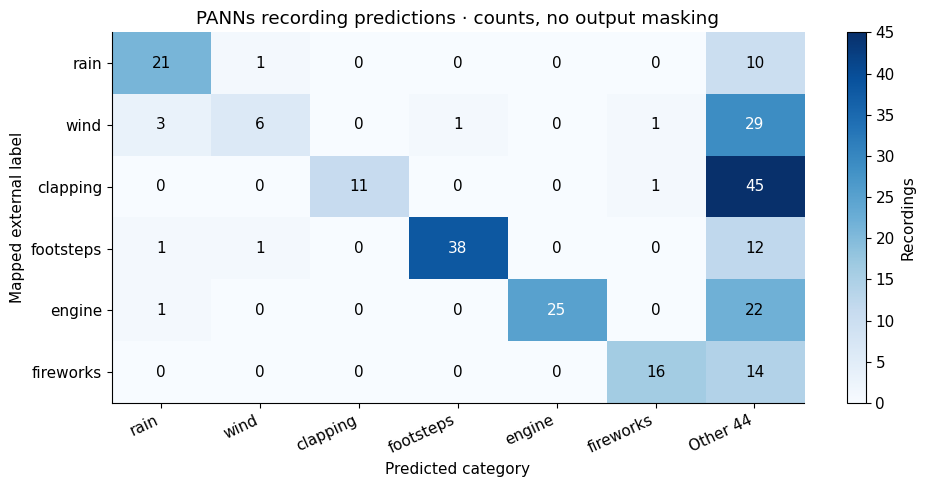

model,target,prediction,Recordings
panns_lr,22,34,30
noise_cnn_s202,22,39,20
noise_cnn_s303,22,39,16
noise_cnn_s101,22,39,15
noise_cnn_s202,48,39,13
noise_cnn_s303,22,34,12
noise_cnn_s101,22,34,12
noise_cnn_s303,48,39,11
noise_cnn_s101,48,39,11
panns_lr,44,35,10


In [10]:
predictions=pd.read_csv(DATA/"predictions.csv")
panns=predictions[predictions.model=="panns_lr"]
targets=sorted(manifest.target.unique());categories=dict(zip(manifest.target,manifest.category))
matrix=np.zeros((len(targets),len(targets)+1),dtype=int)
for row in panns.itertuples():matrix[targets.index(row.target),targets.index(row.prediction) if row.prediction in targets else -1]+=1
fig,ax=plt.subplots(figsize=(10,5));heat=ax.imshow(matrix,cmap="Blues",aspect="auto")
ax.set_yticks(range(6),[categories[t].replace('_',' ') for t in targets]);ax.set_xticks(range(7),[categories[t].replace('_',' ') for t in targets]+["Other 44"],rotation=25,ha="right")
for i in range(6):
    for j in range(7):ax.text(j,i,str(matrix[i,j]),ha="center",va="center",color="white" if matrix[i,j]>matrix.max()*.55 else "black")
ax.set_xlabel("Predicted category");ax.set_ylabel("Mapped external label");ax.set_title("PANNs recording predictions · counts, no output masking")
fig.colorbar(heat,ax=ax,label="Recordings");fig.tight_layout();fig.savefig(DATA/"external_confusion.png",dpi=180);plt.show()
table(predictions[predictions.target!=predictions.prediction].groupby(["model","target","prediction"]).size().reset_index(name="Recordings").sort_values("Recordings",ascending=False).head(15))

### Descriptive follow-up: duration and error accounting

These diagnostics were added after the one-pass evaluation. They use saved predictions only and do not change the protocol, predictions or primary estimate. Comparing the same six categories reduces the class-set mismatch with the development panel, but each development category has only eight clips and recording/aggregation protocols still differ. It is not a causal estimate of domain-shift damage.

In [11]:
metadata=pd.read_csv(ROOT/"data/ESC-50/meta/esc50.csv")
class_names=metadata.drop_duplicates("target").set_index("target").category.to_dict()
context=[]
for model in metrics.model:
    filename="panns_lr_s0_clean.csv" if model=="panns_lr" else model+"_clean.csv"
    development=pd.read_csv(ROOT/"reports/transfer_followup_20261105"/filename)
    for target in targets:
        a=development[development.target==target]
        b=predictions[(predictions.model==model)&(predictions.target==target)]
        context.append(dict(model=model,target=target,category=class_names[target],development_clips=len(a),external_recordings=len(b),development_recall=float((a.prediction==a.target).mean()),external_recall=float((b.prediction==b.target).mean())))
context=pd.DataFrame(context);context.to_csv(DATA/"same_category_development_context.csv",index=False)
table(context[context.model=="panns_lr"].assign(development_recall=lambda x:100*x.development_recall,external_recall=lambda x:100*x.external_recall).rename(columns={"development_recall":"Development recall (%)","external_recall":"External recall (%)"}))

model,target,category,development_clips,external_recordings,Development recall (%),External recall (%)
panns_lr,10,rain,8,32,100.00,65.62
panns_lr,16,wind,8,40,50.00,15.00
panns_lr,22,clapping,8,57,100.00,19.30
panns_lr,25,footsteps,8,52,62.50,73.08
panns_lr,44,engine,8,48,87.50,52.08
panns_lr,48,fireworks,8,30,100.00,53.33


In [12]:
recordings=pd.read_csv(DATA/"recordings.csv")
joined=predictions.merge(recordings[["filename","seconds","windows"]],on="filename",validate="many_to_one")
joined["correct"]=joined.prediction==joined.target
joined["duration_group"]=np.where(joined.seconds<5,"Under 5 seconds","At least 5 seconds")
durations=joined.groupby(["model","duration_group"]).agg(recordings=("filename","size"),accuracy=("correct","mean"),median_seconds=("seconds","median")).reset_index()
durations.to_csv(DATA/"duration_slices.csv",index=False)
table(durations.assign(accuracy=lambda x:100*x.accuracy).rename(columns={"accuracy":"Accuracy (%)"}))
display(Markdown("PANNs accuracy is **27.62% on 105 recordings under five seconds** and **57.14% on 154 longer recordings**. Duration, class composition, recording content and padding vary together. This association does not establish that padding causes the errors, and no short recordings are removed."))

model,duration_group,recordings,Accuracy (%),median_seconds
noise_cnn_s101,At least 5 seconds,154,24.68,8.74
noise_cnn_s101,Under 5 seconds,105,10.48,1.93
noise_cnn_s202,At least 5 seconds,154,29.87,8.74
noise_cnn_s202,Under 5 seconds,105,9.52,1.93
noise_cnn_s303,At least 5 seconds,154,25.97,8.74
noise_cnn_s303,Under 5 seconds,105,10.48,1.93
panns_lr,At least 5 seconds,154,57.14,8.74
panns_lr,Under 5 seconds,105,27.62,1.93


PANNs accuracy is **27.62% on 105 recordings under five seconds** and **57.14% on 154 longer recordings**. Duration, class composition, recording content and padding vary together. This association does not establish that padding causes the errors, and no short recordings are removed.

In [13]:
accounting=[]
for (model,target),group in predictions.groupby(["model","target"]):
    correct=(group.prediction==group.target)
    outside=~group.prediction.isin(targets)
    accounting.append(dict(model=model,target=target,category=class_names[target],recordings=len(group),correct=int(correct.sum()),within_six_errors=int((~correct&~outside).sum()),outside_six_errors=int(outside.sum())))
accounting=pd.DataFrame(accounting);accounting.to_csv(DATA/"error_accounting_by_class.csv",index=False)
totals=accounting.groupby("model")[["recordings","correct","within_six_errors","outside_six_errors"]].sum().reset_index()
totals.to_csv(DATA/"error_accounting.csv",index=False);table(totals)
errors=predictions[(predictions.model=="panns_lr")&(predictions.target!=predictions.prediction)].copy()
errors["true_category"]=errors.target.map(class_names);errors["predicted_category"]=errors.prediction.map(class_names)
patterns=errors.groupby(["true_category","predicted_category"]).size().reset_index(name="recordings").sort_values("recordings",ascending=False)
patterns.to_csv(DATA/"panns_error_patterns.csv",index=False);table(patterns.head(10))
display(Markdown("PANNs has **117 correct, 10 within-six errors and 132 outside-six errors**. The noise-CNN mean is **52 correct, 20.33 within-six errors and 186.67 outside-six errors**. The +65 mean-correct difference equals 54.67 fewer outside-six errors plus 10.33 fewer within-six errors. This is arithmetic error accounting, not a causal explanation or a restricted-label evaluation. Clapping → can opening occurs on 30 recordings; audio inspection would be needed to explain why."))

model,recordings,correct,within_six_errors,outside_six_errors
noise_cnn_s101,259,49,25,185
noise_cnn_s202,259,56,14,189
noise_cnn_s303,259,51,22,186
panns_lr,259,117,10,132


true_category,predicted_category,recordings
clapping,can_opening,30
engine,washing_machine,10
wind,crackling_fire,7
fireworks,can_opening,6
wind,crickets,6
rain,water_drops,5
clapping,crow,4
clapping,breathing,3
wind,rain,3
rain,crickets,3


PANNs has **117 correct, 10 within-six errors and 132 outside-six errors**. The noise-CNN mean is **52 correct, 20.33 within-six errors and 186.67 outside-six errors**. The +65 mean-correct difference equals 54.67 fewer outside-six errors plus 10.33 fewer within-six errors. This is arithmetic error accounting, not a causal explanation or a restricted-label evaluation. Clapping → can opening occurs on 30 recordings; audio inspection would be needed to explain why.

## Takeaways

This is a one-pass evaluation of existing frozen systems. Interpret any accuracy advantage as a comparison on **259 mapped external recordings**, with known ESC-50 recording IDs removed. It does not identify which part of external pretraining, capacity, frontend or learning recipe causes a difference.

The recording length, category composition and aggregation protocol differ from the earlier five-second ESC-50 panel, so changes in aggregate accuracy are not a controlled estimate of domain-shift damage. Reliable annotations do not guarantee identical ontology or acoustic isolation.

Do not tune or select another classifier from these results. The next distinct scientific question is performance with independently recorded, realistic interfering noise, or a broader compatible external label set. Neither is claimed completed by this notebook.

In [14]:
receipt={k:summary[k] for k in ["status","recordings","unique_recording_ids","classes","windows","fits","added_noise","esc50_waveforms_read","all50_output_classes","aggregation","inference_seconds","environment"]}
print(json.dumps(receipt,indent=2))

{
  "status": "completed",
  "recordings": 259,
  "unique_recording_ids": 259,
  "classes": 6,
  "windows": 534,
  "fits": 0,
  "added_noise": false,
  "esc50_waveforms_read": 0,
  "all50_output_classes": true,
  "aggregation": "valid-duration-weighted probabilities",
  "inference_seconds": 28.97557369699996,
  "environment": {
    "python": "3.13.16",
    "numpy": "2.4.6",
    "torch": "2.11.0+cu130",
    "device": "Tesla T4"
  }
}
